# CICIoT2023 Feature-Augmented DNN — five-Seed Final Evaluation

## 1. Environment and reproducibility


In [1]:
import platform
# Global reproducibility setup
import os
import random
import numpy as np
import tensorflow as tf
import sklearn

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("Global seed set to:", SEED)


Global seed set to: 42


In [2]:
import pandas as pd
import numpy as np
import sklearn, os
from sklearn.preprocessing import StandardScaler # RobustScaler
import matplotlib.pyplot as plt  # for plotting
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve, auc
from tensorflow.keras.optimizers import Adam

from sklearn.preprocessing import LabelEncoder
import seaborn as sns 
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import time


## 2. Data preprocessing and feature augmentation

The cells below retain the original preprocessing order and diagnostic outputs.


### Directly clean Augmented data 


In [3]:
# ============================================================
# Load the augmented partitions
train_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Train.csv"
)

validation_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Validation.csv"
)

test_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Test.csv"
)


print(f"Training data:   {train_data.shape}")
print(f"Validation data: {validation_data.shape}")
print(f"Test data:       {test_data.shape}")

display(train_data.head())


Training data:   (354737, 36)
Validation data: (118246, 36)
Test data:       (118246, 36)


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Drate,fin_flag_number,syn_flag_number,psh_flag_number,ack_flag_number,...,Max,AVG,Tot size,IAT,Covariance,Variance,IF_Anomaly_Score,AE_Anomaly_Score,SUOD_Anomaly_Score,label
0,0.244612,38791.0,17.00,64.00,3202.228500,0.0,0.0,0.0,0.0,0.0,...,50.00,50.00000,50.00,83102420.0,0.000000,0.00,0.275168,0.004453,-0.277339,DDoS
1,0.014093,5675.0,17.00,64.00,8785.439000,0.0,0.0,0.0,0.0,0.0,...,50.00,50.00000,50.00,83123740.0,0.000000,0.00,0.283322,0.004197,-0.291433,DDoS
2,0.000000,0.0,47.00,64.00,218.863710,0.0,0.0,0.0,0.0,0.0,...,592.00,592.00000,592.00,83698550.0,0.000000,0.00,0.161012,0.083652,0.648249,Mirai
3,0.000000,54.0,6.00,64.00,3.887012,0.0,0.0,0.0,0.0,0.0,...,54.00,54.00000,54.00,83064136.0,0.000000,0.00,0.319291,0.000523,-0.766263,DDoS
4,0.000000,0.0,0.99,63.36,5.231067,0.0,0.0,0.0,0.0,0.0,...,43.98,42.13838,42.18,83150650.0,2.315749,0.11,0.216951,0.004651,0.238320,DDoS


In [4]:
# ============================================================
# Validate augmented dataset structure
# ============================================================
LABEL_COLUMN = "label"

required_anomaly_features = [
    "IF_Anomaly_Score",
    "AE_Anomaly_Score",
    "SUOD_Anomaly_Score"
]


# Confirm that the label exists in every partition
for dataset_name, dataset in {
    "Training": train_data,
    "Validation": validation_data,
    "Test": test_data
}.items():

    if LABEL_COLUMN not in dataset.columns:
        raise KeyError(
            f"'{LABEL_COLUMN}' was not found in the "
            f"{dataset_name} dataset."
        )


# Extract training feature names
feature_columns = [
    column
    for column in train_data.columns
    if column != LABEL_COLUMN
]


# Confirm that all anomaly-score features exist
missing_anomaly_features = [
    feature
    for feature in required_anomaly_features
    if feature not in feature_columns
]

if missing_anomaly_features:
    raise KeyError(
        "Missing anomaly-score features: "
        f"{missing_anomaly_features}"
    )


# Confirm that all partitions contain identical features
validation_feature_columns = [
    column
    for column in validation_data.columns
    if column != LABEL_COLUMN
]

test_feature_columns = [
    column
    for column in test_data.columns
    if column != LABEL_COLUMN
]

if set(feature_columns) != set(validation_feature_columns):
    raise ValueError(
        "Training and validation feature columns do not match."
    )

if set(feature_columns) != set(test_feature_columns):
    raise ValueError(
        "Training and test feature columns do not match."
    )


print("Dataset validation completed successfully.")
print(f"Number of augmented features: {len(feature_columns)}")
print(f"Training instances: {len(train_data):,}")
print(f"Validation instances: {len(validation_data):,}")
print(f"Test instances: {len(test_data):,}")

print("\nAnomaly-score features:")
for feature in required_anomaly_features:
    print(f"- {feature}")


Dataset validation completed successfully.
Number of augmented features: 35
Training instances: 354,737
Validation instances: 118,246
Test instances: 118,246

Anomaly-score features:
- IF_Anomaly_Score
- AE_Anomaly_Score
- SUOD_Anomaly_Score


### Separate augmented features and multiclass labels


In [5]:
# import numpy as np

# from sklearn.preprocessing import LabelEncoder


# ============================================================
# Extract augmented feature matrices
# ============================================================
# feature_columns were defined in the validation cell.
# Selecting these columns preserves the training column order.
X_train = train_data[
    feature_columns
].copy()

X_val = validation_data[
    feature_columns
].copy()

X_test = test_data[
    feature_columns
].copy()


# ============================================================
# Validate numeric feature values
# ============================================================
for dataset_name, feature_data in {
    "Training": X_train,
    "Validation": X_val,
    "Test": X_test
}.items():

    non_numeric_columns = feature_data.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    if non_numeric_columns:
        raise TypeError(
            f"{dataset_name} data contain non-numeric "
            f"features: {non_numeric_columns}"
        )

    if not np.isfinite(
        feature_data.to_numpy(dtype=np.float32)
    ).all():
        raise ValueError(
            f"{dataset_name} features contain missing "
            "or infinite values."
        )


# ============================================================
# Extract original multiclass labels
# ============================================================
y_train_original = (
    train_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_val_original = (
    validation_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_test_original = (
    test_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)


print(f"Training features:   {X_train.shape}")
print(f"Validation features: {X_val.shape}")
print(f"Test features:       {X_test.shape}")

print(
    f"\nNumber of training classes: "
    f"{y_train_original.nunique()}"
)

display(y_train_original.value_counts())


Training features:   (354737, 35)
Validation features: (118246, 35)
Test features:       (118246, 35)

Number of training classes: 8


label
DDoS          258100
DoS            61405
Mirai          20231
Benign          8248
Spoofing        3729
Recon           2736
Web              188
BruteForce       100
Name: count, dtype: int64

#### Encode the multiclass labels


In [6]:
# ============================================================
# Fit the label encoder on training labels only
# ============================================================
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(
    y_train_original
)


# ============================================================
# Check for unknown validation or test classes
# ============================================================
training_classes = set(
    label_encoder.classes_
)

unknown_validation_classes = (
    set(y_val_original.unique())
    - training_classes
)

unknown_test_classes = (
    set(y_test_original.unique())
    - training_classes
)

if unknown_validation_classes:
    raise ValueError(
        "Validation data contain classes that are absent "
        f"from training: {sorted(unknown_validation_classes)}"
    )

if unknown_test_classes:
    raise ValueError(
        "Test data contain classes that are absent "
        f"from training: {sorted(unknown_test_classes)}"
    )


# Transform validation and test labels using the same encoder
y_val = label_encoder.transform(
    y_val_original
)

y_test = label_encoder.transform(
    y_test_original
)


# ============================================================
# Display multiclass mapping
# ============================================================
print("Multiclass label mapping:")

for class_code, class_name in enumerate(
    label_encoder.classes_
):
    print(f"{class_code}: {class_name}")


number_of_classes = len(
    label_encoder.classes_
)

print(
    f"\nNumber of multiclass target classes: "
    f"{number_of_classes}"
)


Multiclass label mapping:
0: Benign
1: BruteForce
2: DDoS
3: DoS
4: Mirai
5: Recon
6: Spoofing
7: Web

Number of multiclass target classes: 8


#### Standardize the augmented features


In [7]:
from sklearn.preprocessing import StandardScaler


# ============================================================
# Fit the scaler on augmented training features only
# ============================================================
classifier_scaler = StandardScaler()

X_train_scaled = classifier_scaler.fit_transform(
    X_train
).astype(np.float32)


# Apply the same fitted scaler without refitting
X_val_scaled = classifier_scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = classifier_scaler.transform(
    X_test
).astype(np.float32)


# ============================================================
# Verify scaled data
# ============================================================
if not np.isfinite(X_train_scaled).all():
    raise ValueError(
        "Scaled training features contain invalid values."
    )

if not np.isfinite(X_val_scaled).all():
    raise ValueError(
        "Scaled validation features contain invalid values."
    )

if not np.isfinite(X_test_scaled).all():
    raise ValueError(
        "Scaled test features contain invalid values."
    )


print(f"Scaled training features:   {X_train_scaled.shape}")
print(f"Scaled validation features: {X_val_scaled.shape}")
print(f"Scaled test features:       {X_test_scaled.shape}")

print(
    f"\nTraining mean after scaling: "
    f"{X_train_scaled.mean():.6f}"
)

print(
    f"Training standard deviation after scaling: "
    f"{X_train_scaled.std():.6f}"
)


Scaled training features:   (354737, 35)
Scaled validation features: (118246, 35)
Scaled test features:       (118246, 35)

Training mean after scaling: 0.000000
Training standard deviation after scaling: 1.000000


## 3. One-time Optuna hyperparameter optimization


## 4. Deep Neural Network (DNN)

### Optional DNN hyperparameter optimization

The original DNN Optuna optimization structure is retained.

- `RUN_OPTUNA = False`: load the previously stored optimized parameters.
- `RUN_OPTUNA = True`: run a new Optuna search and save the new best parameters.

The optimization uses the training and validation partitions only. The test
partition is not used during hyperparameter selection.


In [8]:
# ============================================================
# DNN optimization control
# ============================================================

# False -> use the previously stored optimized parameters.
# True  -> run a new Optuna search and save the new parameters.
RUN_OPTUNA = False

N_OPTUNA_TRIALS = 25

# Existing parameter file in the read-only Kaggle input dataset.
PRESTORED_PARAMS_DNN_FILE = (
    "/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/best_params_dnn_imbalanceCIC2023.json"
)

# New parameter file created by the current notebook.
# /kaggle/working is writable.
NEW_PARAMS_DNN_FILE = (
    "/kaggle/working/"
    "best_params_dnn_imbalanceCIC2023.json"
)

print(f"RUN_OPTUNA = {RUN_OPTUNA}")

if RUN_OPTUNA:
    print(
        "New DNN parameter file:",
        NEW_PARAMS_DNN_FILE,
    )
else:
    print(
        "Pre-stored DNN parameter file:",
        PRESTORED_PARAMS_DNN_FILE,
    )


RUN_OPTUNA = False
Pre-stored DNN parameter file: /kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/best_params_dnn_imbalanceCIC2023.json


In [9]:
from sklearn.metrics import f1_score
from tensorflow.keras import regularizers
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam


class SparseMacroF1(tf.keras.metrics.Metric):
    """Dataset-level macro F1 for sparse integer multiclass labels."""

    def __init__(
        self,
        number_of_classes,
        name="macro_f1",
        **kwargs,
    ):
        super().__init__(
            name=name,
            **kwargs,
        )

        self.number_of_classes = int(
            number_of_classes
        )

        self.confusion_matrix = self.add_weight(
            name="confusion_matrix",
            shape=(
                self.number_of_classes,
                self.number_of_classes,
            ),
            initializer="zeros",
            dtype=tf.float32,
        )

    def update_state(
        self,
        y_true,
        y_pred,
        sample_weight=None,
    ):
        y_true = tf.cast(
            tf.reshape(
                y_true,
                [-1],
            ),
            tf.int32,
        )

        y_pred = tf.argmax(
            y_pred,
            axis=1,
            output_type=tf.int32,
        )

        weights = None

        if sample_weight is not None:
            weights = tf.cast(
                tf.reshape(
                    sample_weight,
                    [-1],
                ),
                tf.float32,
            )

        batch_confusion_matrix = (
            tf.math.confusion_matrix(
                y_true,
                y_pred,
                num_classes=(
                    self.number_of_classes
                ),
                weights=weights,
                dtype=tf.float32,
            )
        )

        self.confusion_matrix.assign_add(
            batch_confusion_matrix
        )

    def result(self):
        true_positives = (
            tf.linalg.diag_part(
                self.confusion_matrix
            )
        )

        false_positives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=0,
            )
            - true_positives
        )

        false_negatives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=1,
            )
            - true_positives
        )

        class_f1 = tf.math.divide_no_nan(
            2.0 * true_positives,
            2.0 * true_positives
            + false_positives
            + false_negatives,
        )

        return tf.reduce_mean(
            class_f1
        )

    def reset_state(self):
        self.confusion_matrix.assign(
            tf.zeros_like(
                self.confusion_matrix
            )
        )

    def get_config(self):
        config = super().get_config()

        config.update(
            {
                "number_of_classes":
                    self.number_of_classes
            }
        )

        return config


In [10]:
# ============================================================
# Recommended DNN Optuna objective and search space
# ============================================================

# Fixed maximum number of epochs for every Optuna trial and
# every final seed run. The effective number of epochs is
# determined independently by early stopping.
MAX_EPOCHS_DNN = 100

# Early-stopping settings kept identical across optimization
# and final five-seed training.
EARLY_STOPPING_PATIENCE = 10


def objective_dnn(trial):
    """Train one DNN trial and return validation macro F1."""

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(
        SEED + trial.number
    )

    # --------------------------------------------------------
    # Architecture-specific search space
    # --------------------------------------------------------
    hidden_layer1_dnn = trial.suggest_int(
        "hidden_layer1_dnn",
        32,
        128,
        step=16,
    )

    hidden_layer2_dnn = trial.suggest_int(
        "hidden_layer2_dnn",
        16,
        64,
        step=16,
    )

    # --------------------------------------------------------
    # Shared optimization search space
    # --------------------------------------------------------
    dropout_rate_dnn = trial.suggest_float(
        "dropout_rate_dnn",
        0.1,
        0.4,
        step=0.1,
    )

    batch_size_dnn = trial.suggest_categorical(
        "batch_size_dnn",
        [64, 128, 256, 512],
    )

    learning_rate_dnn = trial.suggest_float(
        "learning_rate_dnn",
        1e-5,
        1e-2,
        log=True,
    )

    l2_reg = trial.suggest_float(
        "l2_reg",
        1e-6,
        1e-3,
        log=True,
    )

    model_dnn_trial = Sequential(
        [
            Input(
                shape=(
                    X_train_scaled.shape[1],
                )
            ),

            Dense(
                hidden_layer1_dnn,
                activation="relu",
                kernel_regularizer=(
                    regularizers.l2(
                        l2_reg
                    )
                ),
            ),

            Dropout(
                dropout_rate_dnn
            ),

            Dense(
                hidden_layer2_dnn,
                activation="relu",
                kernel_regularizer=(
                    regularizers.l2(
                        l2_reg
                    )
                ),
            ),

            Dropout(
                dropout_rate_dnn
            ),

            Dense(
                number_of_classes,
                activation="softmax",
            ),
        ],
        name="DNN_Optuna_Trial",
    )

    model_dnn_trial.compile(
        loss="sparse_categorical_crossentropy",

        optimizer=Adam(
            learning_rate=(
                learning_rate_dnn
            )
        ),

        metrics=[
            "accuracy",

            SparseMacroF1(
                number_of_classes
            ),
        ],
    )

    # --------------------------------------------------------
    # Fixed maximum epochs + validation-based early stopping
    # --------------------------------------------------------
    model_dnn_trial.fit(
        X_train_scaled,
        y_train,

        epochs=MAX_EPOCHS_DNN,

        batch_size=batch_size_dnn,

        validation_data=(
            X_val_scaled,
            y_val,
        ),

        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=EARLY_STOPPING_PATIENCE,
                restore_best_weights=True,
            ),

            KerasPruningCallback(
                trial,
                monitor="val_macro_f1",
                interval=1,
            ),
        ],

        shuffle=True,
        verbose=0,
    )

    validation_probabilities = (
        model_dnn_trial.predict(
            X_val_scaled,
            verbose=0,
        )
    )

    validation_predictions = np.argmax(
        validation_probabilities,
        axis=1,
    )

    validation_macro_f1 = f1_score(
        y_val,
        validation_predictions,

        labels=np.arange(
            number_of_classes
        ),

        average="macro",
        zero_division=0,
    )

    del model_dnn_trial

    tf.keras.backend.clear_session()

    return float(
        validation_macro_f1
    )


In [12]:
# !pip install optuna-integration[keras]

In [13]:
# ============================================================
# Execute optional DNN Optuna optimization
# ============================================================

if RUN_OPTUNA:

    import optuna
    from optuna.trial import TrialState

    # Current Optuna versions provide integrations through
    # optuna-integration. The fallback supports older versions.
    try:
        from optuna_integration import (
            KerasPruningCallback
        )
    except ImportError:
        from optuna.integration import (
            KerasPruningCallback
        )

    # TPE sampling and median-based early pruning.
    study_dnn = optuna.create_study(
        direction="maximize",
        sampler=(
            optuna.samplers.TPESampler(
                seed=SEED
            )
        ),
        pruner=(
            optuna.pruners.MedianPruner(
                n_startup_trials=5,
                n_warmup_steps=10,
                interval_steps=1,
            )
        ),
    )

    study_dnn.optimize(
        objective_dnn,
        n_trials=N_OPTUNA_TRIALS,
        n_jobs=1,
        gc_after_trial=True,
    )

    complete_trials_dnn = (
        study_dnn.get_trials(
            deepcopy=False,
            states=[
                TrialState.COMPLETE
            ],
        )
    )

    pruned_trials_dnn = (
        study_dnn.get_trials(
            deepcopy=False,
            states=[
                TrialState.PRUNED
            ],
        )
    )

    failed_trials_dnn = (
        study_dnn.get_trials(
            deepcopy=False,
            states=[
                TrialState.FAIL
            ],
        )
    )

    print(
        "Best DNN hyperparameters:",
        study_dnn.best_params,
    )

    print(
        "Best DNN validation macro F1: "
        f"{study_dnn.best_value:.6f}"
    )

    print(
        "DNN study statistics:"
    )

    print(
        "  Number of finished trials:",
        len(
            study_dnn.trials
        ),
    )

    print(
        "  Number of complete trials:",
        len(
            complete_trials_dnn
        ),
    )

    print(
        "  Number of pruned trials:",
        len(
            pruned_trials_dnn
        ),
    )

    print(
        "  Number of failed trials:",
        len(
            failed_trials_dnn
        ),
    )

    best_trial_dnn = (
        study_dnn.best_trial
    )

    print(
        "  Best validation macro F1: "
        f"{best_trial_dnn.value:.6f}"
    )

    print(
        "  Best parameters:"
    )

    for (
        key,
        value,
    ) in best_trial_dnn.params.items():
        print(
            f"    {key}: {value}"
        )

    # Preserve the original DNN parameter variable name.
    best_params_dnn = (
        study_dnn.best_params
    )

    with open(
        NEW_PARAMS_DNN_FILE,
        "w",
        encoding="utf-8",
    ) as json_file:
        json.dump(
            best_params_dnn,
            json_file,
            indent=2,
        )

    print(
        "New optimized DNN parameters saved to:",
        NEW_PARAMS_DNN_FILE,
    )

else:
    print(
        "Optuna optimization skipped. "
        "Using the pre-stored DNN parameters."
    )


Optuna optimization skipped. Using the pre-stored DNN parameters.


### Load the optimized DNN parameters for final training

This cell is always executed.

- With `RUN_OPTUNA = False`, it loads the existing pre-stored JSON.
- With `RUN_OPTUNA = True`, it loads the newly optimized JSON saved above.

The original final-training variable name `best_params_dnn` is retained.


In [16]:
# ============================================================
# Select optimized DNN parameter file
# ============================================================

if RUN_OPTUNA:
    # Load the parameters generated by the current Optuna run.
    BEST_PARAMS_DNN_FILE = (
        NEW_PARAMS_DNN_FILE
    )
else:
    # Load the previously stored optimized parameters.
    BEST_PARAMS_DNN_FILE = (
        PRESTORED_PARAMS_DNN_FILE
    )

print(
    "DNN parameter file selected:",
    BEST_PARAMS_DNN_FILE,
)


DNN parameter file selected: /kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/best_params_dnn_imbalanceCIC2023.json


In [17]:
import json

# Load the optimized DNN hyperparameters for final training.
with open(
    BEST_PARAMS_DNN_FILE,
    "r",
    encoding="utf-8",
) as json_file:
    best_params_dnn = json.load(
        json_file
    )

print(
    "DNN hyperparameters loaded successfully."
)

best_params_dnn


DNN hyperparameters loaded successfully.


{'best_params': {'hidden_layer1_dnn': 128,
  'hidden_layer2_dnn': 64,
  'dropout_rate_dnn': 0.2,
  'batch_size_dnn': 128,
  'learning_rate_dnn': 0.00037803826453175314,
  'l2_reg': 1.970202854460587e-06},
 'best_validation_macro_f1': 0.712634292453566,
 'best_trial_number': 22,
 'number_of_trials': 25}

In [18]:
import json

with open(BEST_PARAMS_DNN_FILE, "r", encoding="utf-8") as f:
    loaded_params = json.load(f)

best_params_dnn = loaded_params.get(
    "best_params",
    loaded_params
)

print("Loaded DNN hyperparameters:")
print(best_params_dnn)

Loaded DNN hyperparameters:
{'hidden_layer1_dnn': 128, 'hidden_layer2_dnn': 64, 'dropout_rate_dnn': 0.2, 'batch_size_dnn': 128, 'learning_rate_dnn': 0.00037803826453175314, 'l2_reg': 1.970202854460587e-06}


## 5. Five-run final DNN training and evaluation

The same training, validation, and test partitions and the same optimized DNN
hyperparameters are used for every run. 

In [20]:
from pathlib import Path
import gc
import joblib

from sklearn.metrics import (
    matthews_corrcoef,
    multilabel_confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)


# ============================================================
# Repeated-run protocol
# ============================================================
RUN_SEEDS = [42, 43, 44, 45, 46]

N_FINAL_RUNS = len(
    RUN_SEEDS
)

N_WARMUP_RUNS = 3
# ADDED/UPDATED FOR JOURNAL INFERENCE BENCHMARKING
# Five timed full-test repetitions are used per trained seed model.
N_BENCHMARK_RUNS = 5

REPORT_OUTPUT_DIRECTORY = (
    Path.cwd()
    / "CICIoT2023_DNN_5_seed_V3"
)

# Retain the original variable name.
MODEL_OUTPUT_DIRECTORY = (
    REPORT_OUTPUT_DIRECTORY
)

REPORT_OUTPUT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# Environment metadata for inference-time reproducibility
# ============================================================
environment_metadata = {
    "python_version":
        platform.python_version(),

    "tensorflow_version":
        tf.__version__,

    "numpy_version":
        np.__version__,

    "pandas_version":
        pd.__version__,

    "scikit_learn_version":
        sklearn.__version__,

    "platform":
        platform.platform(),

    "processor":
        platform.processor(),

    "machine":
        platform.machine(),

    "tensorflow_devices": [
        {
            "name":
                device.name,

            "device_type":
                device.device_type,
        }
        for device
        in tf.config.list_physical_devices()
    ],
}

ENVIRONMENT_METADATA_PATH = (
    REPORT_OUTPUT_DIRECTORY
    / "environment_metadata.json"
)

with open(
    ENVIRONMENT_METADATA_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        environment_metadata,
        f,
        indent=2,
    )

print(
    "Environment metadata saved to:",
    ENVIRONMENT_METADATA_PATH,
)


# ============================================================
# ADDED FOR REPRODUCIBILITY
# Save preprocessing and exact test inputs required to
# regenerate predictions and benchmark the pretrained models
# later without refitting the scaler or rebuilding the test set.
# ============================================================

# Save the scaler fitted on the training partition only.
joblib.dump(
    classifier_scaler,
    REPORT_OUTPUT_DIRECTORY
    / "classifier_scaler.joblib",
)

# Save the exact ordered feature list expected by the DNN.
with open(
    REPORT_OUTPUT_DIRECTORY
    / "feature_columns.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        list(feature_columns),
        json_file,
        indent=2,
    )

# Save the multiclass label ordering/mapping.
with open(
    REPORT_OUTPUT_DIRECTORY
    / "class_names.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        label_encoder.classes_.tolist(),
        json_file,
        indent=2,
    )

# Save the exact scaled test matrix used during evaluation.
# This allows inference benchmarking on another machine using
# exactly the same model input without repeating preprocessing.
np.save(
    REPORT_OUTPUT_DIRECTORY
    / "X_test_scaled.npy",
    X_test_scaled,
)

# Save the exact encoded test labels for metric regeneration.
np.save(
    REPORT_OUTPUT_DIRECTORY
    / "y_test.npy",
    y_test,
)

# Save the optimized DNN hyperparameters together with the
# experiment outputs for a self-contained reproducibility folder.
with open(
    REPORT_OUTPUT_DIRECTORY
    / "best_params_dnn_imbalanceCIC2023.json",
    "w",
    encoding="utf-8",
) as json_file:
    json.dump(
        best_params_dnn,
        json_file,
        indent=2,
    )

print(
    "Saved global reproducibility artifacts to:",
    REPORT_OUTPUT_DIRECTORY.resolve(),
)


def set_final_run_seed(seed):
    """Reset Python, NumPy, and TensorFlow random states for one run."""

    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    tf.keras.utils.set_random_seed(
        seed
    )


try:
    tf.config.experimental.enable_op_determinism()

    print(
        "TensorFlow deterministic operations enabled."
    )

except (
    AttributeError,
    RuntimeError,
):
    print(
        "TensorFlow deterministic-operation control "
        "is unavailable in this environment."
    )


def benchmark_full_test_prediction(
    model,
    X_input,
):
    """Measure full-test inference with the original timing protocol."""

    warmup_size = min(
        1024,
        len(X_input),
    )

    for _ in range(
        N_WARMUP_RUNS
    ):
        model.predict(
            X_input[
                :warmup_size
            ],
            verbose=0,
        )

    measured_times = []
    probabilities = None

    for _ in range(
        N_BENCHMARK_RUNS
    ):
        start_time = (
            time.perf_counter()
        )

        probabilities = (
            model.predict(
                X_input,
                verbose=0,
            )
        )

        measured_times.append(
            time.perf_counter()
            - start_time
        )

    measured_times = np.asarray(
        measured_times,
        dtype=float,
    )

    mean_inference_time = float(
        measured_times.mean()
    )

    # ADDED FOR REPRODUCIBILITY
    # Retain timing variability across the repeated benchmark
    # passes performed for this trained seed model.
    sd_inference_time = float(
        measured_times.std(
            ddof=1
        )
    )

    mean_latency = (
        mean_inference_time
        / len(X_input)
        * 1000.0
    )

    sd_latency = (
        sd_inference_time
        / len(X_input)
        * 1000.0
    )

    return probabilities, {
        "Inference_Time_s":
            mean_inference_time,

        "Inference_Time_SD_s":
            sd_inference_time,

        "Latency_ms_per_sample":
            mean_latency,

        "Latency_SD_ms_per_sample":
            sd_latency,

        "Throughput_samples_per_s":
            (
                len(X_input)
                / mean_inference_time
            ),

        "Inference_Benchmark_Runs":
            N_BENCHMARK_RUNS,
    }, measured_times


def calculate_fpr_metrics(
    y_true,
    y_pred,
    labels,
):
    """Calculate macro, micro/overall, and support-weighted multiclass FPR."""

    matrices = (
        multilabel_confusion_matrix(
            y_true,
            y_pred,
            labels=labels,
        )
    )

    per_class_fpr = []
    false_positives = []
    true_negatives = []

    for matrix in matrices:
        (
            true_negative,
            false_positive,
            _,
            _,
        ) = matrix.ravel()

        denominator = (
            false_positive
            + true_negative
        )

        per_class_fpr.append(
            (
                false_positive
                / denominator
            )
            if denominator
            else 0.0
        )

        false_positives.append(
            false_positive
        )

        true_negatives.append(
            true_negative
        )

    per_class_fpr = np.asarray(
        per_class_fpr,
        dtype=float,
    )

    false_positives = np.asarray(
        false_positives,
        dtype=float,
    )

    true_negatives = np.asarray(
        true_negatives,
        dtype=float,
    )

    supports = np.asarray(
        [
            (y_true == label).sum()
            for label in labels
        ],
        dtype=float,
    )

    micro_denominator = (
        false_positives.sum()
        + true_negatives.sum()
    )

    return {
        "FPR_macro": float(
            per_class_fpr.mean()
        ),

        "FPR_micro_overall": float(
            (
                false_positives.sum()
                / micro_denominator
            )
            if micro_denominator
            else 0.0
        ),

        "FPR_weighted": float(
            np.average(
                per_class_fpr,
                weights=supports,
            )
        ),
    }


def calculate_test_metrics(
    y_true,
    y_pred,
    probabilities,
    labels,
):
    """Calculate scalar test metrics for one independent DNN run."""

    metrics = {
        "Accuracy":
            accuracy_score(
                y_true,
                y_pred,
            ),

        "Precision_macro":
            precision_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            ),

        "Recall_macro":
            recall_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            ),

        "F1_macro":
            f1_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            ),

        "Precision_weighted":
            precision_score(
                y_true,
                y_pred,
                labels=labels,
                average="weighted",
                zero_division=0,
            ),

        "Recall_weighted":
            recall_score(
                y_true,
                y_pred,
                labels=labels,
                average="weighted",
                zero_division=0,
            ),

        "F1_weighted":
            f1_score(
                y_true,
                y_pred,
                labels=labels,
                average="weighted",
                zero_division=0,
            ),

        "MCC":
            matthews_corrcoef(
                y_true,
                y_pred,
            ),
    }

    try:
        metrics[
            "ROC_AUC_macro_OvR"
        ] = roc_auc_score(
            y_true,
            probabilities,
            labels=labels,
            average="macro",
            multi_class="ovr",
        )

    except ValueError as error:
        metrics[
            "ROC_AUC_macro_OvR"
        ] = np.nan

        print(
            "Macro ROC-AUC could not be "
            f"calculated: {error}"
        )

    metrics.update(
        calculate_fpr_metrics(
            y_true,
            y_pred,
            labels,
        )
    )

    return metrics


def format_mean_sd(
    mean_value,
    sd_value,
):
    """Format mean ± sample SD for journal reporting."""

    if pd.isna(
        mean_value
    ):
        return "NA"

    if pd.isna(
        sd_value
    ):
        return (
            f"{mean_value:.6f} ± NA"
        )

    return (
        f"{mean_value:.6f} ± "
        f"{sd_value:.6f}"
    )


def plot_publication_confusion_matrix(
    y_true,
    y_pred,
    output_stem,
):
    """Save confusion matrix as PDF and 600-dpi PNG."""

    matrix = confusion_matrix(
        y_true,
        y_pred,
    )

    plt.figure(
        figsize=(6.8, 5.5)
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=(
            label_encoder.classes_
        ),
        yticklabels=(
            label_encoder.classes_
        ),
    )

    plt.xticks(
        rotation=45,
        ha="right",
        fontsize=10,
    )

    plt.yticks(
        rotation=45,
        fontsize=10,
    )

    plt.xlabel(
        "Predicted Label",
        fontsize=11,
    )

    plt.ylabel(
        "True Label",
        fontsize=11,
    )

    plt.tight_layout()

    plt.savefig(
        f"{output_stem}.pdf",
        bbox_inches="tight",
    )

    plt.savefig(
        f"{output_stem}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()


Environment metadata saved to: /kaggle/working/CICIoT2023_DNN_5_seed_V3/environment_metadata.json
Saved global reproducibility artifacts to: /kaggle/working/CICIoT2023_DNN_5_seed_V3
TensorFlow deterministic operations enabled.


### Final DNN model builder

In [21]:
def build_final_dnn(
    parameters
):
    hidden_layer1 = (
        parameters[
            "hidden_layer1_dnn"
        ]
    )

    model = Sequential(
        [
            Input(
                shape=(
                    X_train_scaled.shape[1],
                )
            ),

            Dense(
                hidden_layer1,
                activation="relu",
                kernel_regularizer=(
                    regularizers.l2(
                        parameters[
                            "l2_reg"
                        ]
                    )
                ),
            ),

            Dropout(
                parameters[
                    "dropout_rate_dnn"
                ]
            ),

            Dense(
                # New Optuna runs optimize the second hidden
                # layer independently. The fallback preserves
                # compatibility with older stored parameter
                # files that used hidden_layer1 // 2.
                parameters.get(
                    "hidden_layer2_dnn",
                    hidden_layer1 // 2,
                ),
                activation="relu",
                kernel_regularizer=(
                    regularizers.l2(
                        parameters[
                            "l2_reg"
                        ]
                    )
                ),
            ),

            Dropout(
                parameters[
                    "dropout_rate_dnn"
                ]
            ),

            Dense(
                number_of_classes,
                activation="softmax",
            ),
        ],
        name="DNN",
    )

    model.compile(
        loss=(
            "sparse_categorical_crossentropy"
        ),

        optimizer=Adam(
            learning_rate=(
                parameters[
                    "learning_rate_dnn"
                ]
            )
        ),

        metrics=[
            "accuracy"
        ],
    )

    return model


### Execute five independent DNN runs


DNN: final run 1/5; seed=42
Epoch 1/100


2026-09-26 20:11:57.584608: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


2762/2772 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7950 - loss: 0.5648

2026-09-26 20:12:06.516665: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


2772/2772 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.8345 - loss: 0.4068 - val_accuracy: 0.8616 - val_loss: 0.3070
Epoch 2/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8593 - loss: 0.3137 - val_accuracy: 0.8669 - val_loss: 0.2811
Epoch 3/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8693 - loss: 0.2859 - val_accuracy: 0.8823 - val_loss: 0.2532
Epoch 4/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8804 - loss: 0.2635 - val_accuracy: 0.8957 - val_loss: 0.2343
Epoch 5/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8905 - loss: 0.2442 - val_accuracy: 0.9046 - val_loss: 0.2161
Epoch 6/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8997 - loss: 0.2263 - val_accuracy: 0.9145 - val_loss: 0.1973
Epoch 7/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9093 - loss: 0.2076 - val_accuracy: 0.9230 - val_loss: 0.1775
Epoch 8/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9199 - loss: 0.1867 - va

2026-09-26 20:24:20.793288: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-26 20:24:27.013170: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

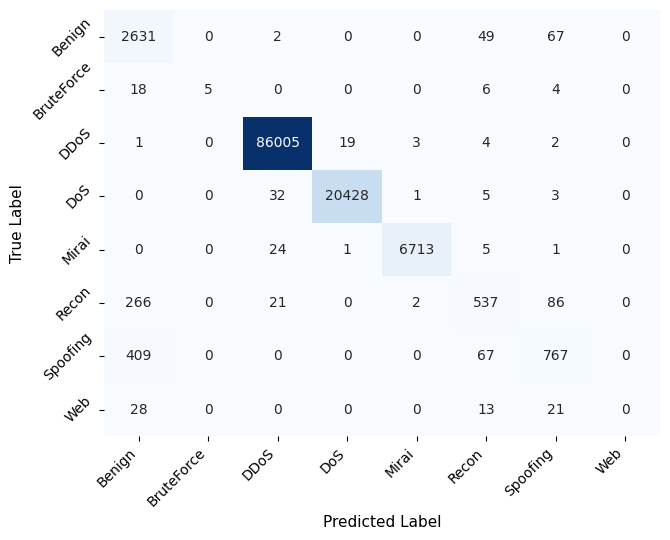

Completed DNN seed 42: test macro F1=0.686488
Saved run results to: /kaggle/working/CICIoT2023_DNN_5_seed_V3/DNN_Seed_1

DNN: final run 2/5; seed=43
Epoch 1/100


2026-09-26 20:25:10.138723: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


2762/2772 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8047 - loss: 0.5278

2026-09-26 20:25:20.261984: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


2772/2772 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.8357 - loss: 0.3956 - val_accuracy: 0.8622 - val_loss: 0.3119
Epoch 2/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8590 - loss: 0.3148 - val_accuracy: 0.8691 - val_loss: 0.2848
Epoch 3/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8682 - loss: 0.2887 - val_accuracy: 0.8752 - val_loss: 0.2605
Epoch 4/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8796 - loss: 0.2648 - val_accuracy: 0.8886 - val_loss: 0.2412
Epoch 5/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8892 - loss: 0.2472 - val_accuracy: 0.9020 - val_loss: 0.2198
Epoch 6/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8984 - loss: 0.2292 - val_accuracy: 0.9130 - val_loss: 0.2019
Epoch 7/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9093 - loss: 0.2094 - val_accuracy: 0.9243 - val_loss: 0.1784
Epoch 8/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9225 - loss: 0.185

2026-09-26 20:41:38.000953: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-26 20:41:43.378624: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

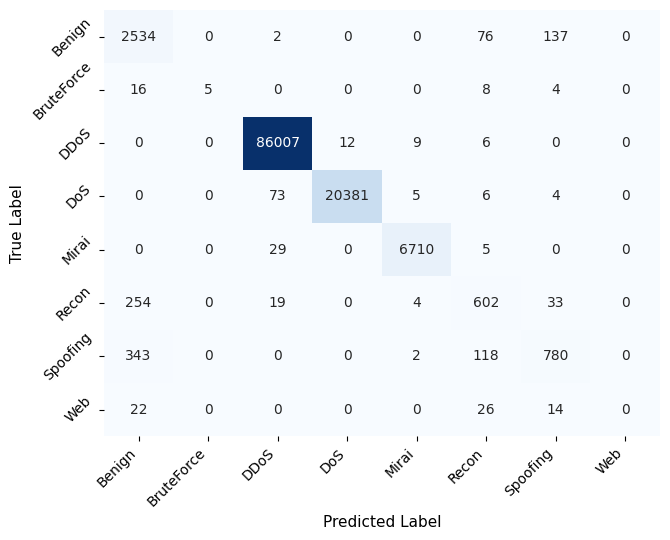

Completed DNN seed 43: test macro F1=0.687621
Saved run results to: /kaggle/working/CICIoT2023_DNN_5_seed_V3/DNN_Seed_2

DNN: final run 3/5; seed=44
Epoch 1/100


2026-09-26 20:42:18.604154: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


2757/2772 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8100 - loss: 0.5243

2026-09-26 20:42:27.515943: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


2772/2772 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8361 - loss: 0.3942 - val_accuracy: 0.8599 - val_loss: 0.3060
Epoch 2/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8592 - loss: 0.3084 - val_accuracy: 0.8713 - val_loss: 0.2741
Epoch 3/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8711 - loss: 0.2799 - val_accuracy: 0.8856 - val_loss: 0.2506
Epoch 4/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8817 - loss: 0.2594 - val_accuracy: 0.8950 - val_loss: 0.2326
Epoch 5/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8903 - loss: 0.2424 - val_accuracy: 0.9028 - val_loss: 0.2144
Epoch 6/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8994 - loss: 0.2259 - val_accuracy: 0.9157 - val_loss: 0.1984
Epoch 7/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9101 - loss: 0.2083 - val_accuracy: 0.9296 - val_loss: 0.1732
Epoch 8/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9242 - loss: 0.1826

2026-09-26 20:58:13.586416: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-26 20:58:18.802901: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

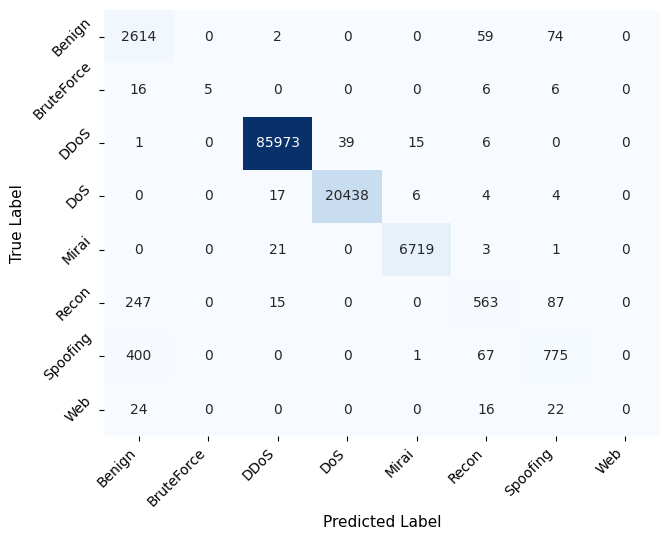

Completed DNN seed 44: test macro F1=0.688783
Saved run results to: /kaggle/working/CICIoT2023_DNN_5_seed_V3/DNN_Seed_3

DNN: final run 4/5; seed=45
Epoch 1/100


2026-09-26 20:58:53.151322: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


2758/2772 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7945 - loss: 0.5616

2026-09-26 20:59:02.128598: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


2772/2772 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8337 - loss: 0.4023 - val_accuracy: 0.8601 - val_loss: 0.3046
Epoch 2/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8596 - loss: 0.3094 - val_accuracy: 0.8709 - val_loss: 0.2762
Epoch 3/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8700 - loss: 0.2832 - val_accuracy: 0.8852 - val_loss: 0.2560
Epoch 4/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8802 - loss: 0.2633 - val_accuracy: 0.8947 - val_loss: 0.2383
Epoch 5/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8893 - loss: 0.2459 - val_accuracy: 0.9001 - val_loss: 0.2210
Epoch 6/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8987 - loss: 0.2268 - val_accuracy: 0.9128 - val_loss: 0.1978
Epoch 7/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9123 - loss: 0.2051 - val_accuracy: 0.9282 - val_loss: 0.1686
Epoch 8/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9279 - loss: 0.178

2026-09-26 21:11:59.041115: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-26 21:12:05.170785: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

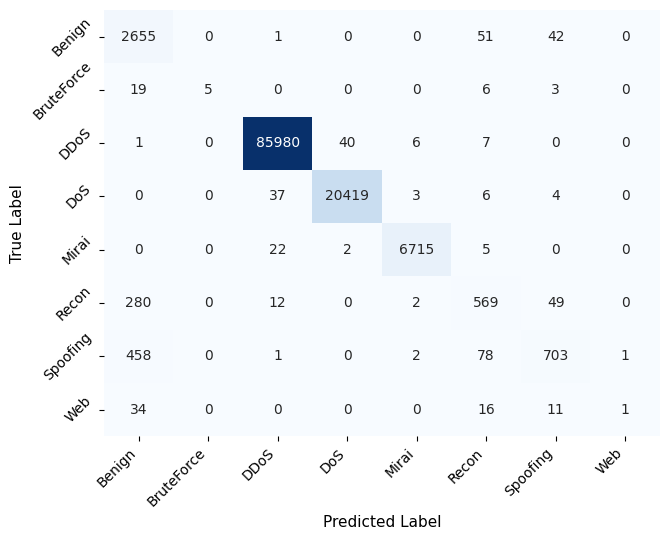

Completed DNN seed 45: test macro F1=0.689899
Saved run results to: /kaggle/working/CICIoT2023_DNN_5_seed_V3/DNN_Seed_4

DNN: final run 5/5; seed=46
Epoch 1/100


2026-09-26 21:12:40.054070: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


2765/2772 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7918 - loss: 0.5552

2026-09-26 21:12:48.614285: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8320 - loss: 0.4039 - val_accuracy: 0.8591 - val_loss: 0.3090
Epoch 2/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8594 - loss: 0.3134 - val_accuracy: 0.8669 - val_loss: 0.2796
Epoch 3/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8703 - loss: 0.2852 - val_accuracy: 0.8819 - val_loss: 0.2541
Epoch 4/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8816 - loss: 0.2625 - val_accuracy: 0.8975 - val_loss: 0.2333
Epoch 5/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8910 - loss: 0.2444 - val_accuracy: 0.9072 - val_loss: 0.2165
Epoch 6/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8990 - loss: 0.2271 - val_accuracy: 0.9161 - val_loss: 0.2005
Epoch 7/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9085 - loss: 0.2108 - val_accuracy: 0.9234 - val_loss: 0.1800
Epoch 8/100
2772/2772 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9185 - loss: 0.1918 -

2026-09-26 21:24:01.837558: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-26 21:24:07.146182: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

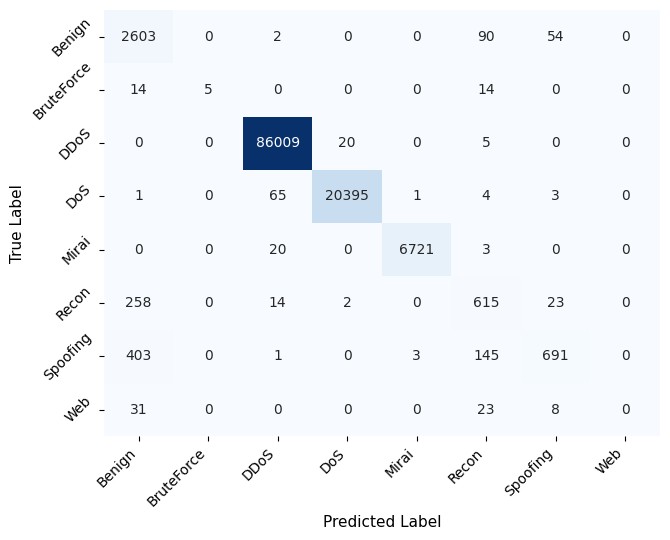

Completed DNN seed 46: test macro F1=0.684994
Saved run results to: /kaggle/working/CICIoT2023_DNN_5_seed_V3/DNN_Seed_5


,Model,Run,Seed,Training_Time_s,Validation_F1_macro,Test_Loss,Accuracy,Precision_macro,Recall_macro,F1_macro,...,ROC_AUC_macro_OvR,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Inference_Time_SD_s,Latency_ms_per_sample,Latency_SD_ms_per_sample,Throughput_samples_per_s,Inference_Benchmark_Runs
0,DNN,1,42,743.314357,0.710758,0.029385,0.990190,0.796400,0.663441,0.686488,...,0.997771,0.001476,0.001401,0.001995,6.294180,0.484129,0.053230,0.004094,18786.562946,5
1,DNN,2,43,987.934792,0.712638,0.029365,0.989623,0.788481,0.668907,0.687621,...,0.997841,0.001668,0.001482,0.002971,5.088737,0.222538,0.043035,0.001882,23236.807600,5
2,DNN,3,44,955.047096,0.711210,0.029226,0.990198,0.795406,0.667161,0.688783,...,0.997979,0.001411,0.001400,0.001489,4.947000,0.328069,0.041837,0.002774,23902.568248,5
3,DNN,4,45,785.945966,0.707462,0.029379,0.989860,0.862771,0.664444,0.689899,...,0.997821,0.001506,0.001449,0.001910,4.972620,0.389315,0.042053,0.003292,23779.416436,5
4,DNN,5,46,681.839713,0.697796,0.030109,0.989792,0.794335,0.665168,0.684994,...,0.997687,0.001590,0.001458,0.002514,5.489649,0.064177,0.046426,0.000543,21539.810526,5


In [24]:
def run_five_seed_experiment(
    model_name,
    model_builder,
    parameters,
    X_train_input,
    X_val_input,
    X_test_input,
    max_epochs,
    batch_size_key,
):
    """Train, evaluate, time, and save the DNN model for five seeds."""

    labels = np.arange(
        number_of_classes
    )

    run_rows = []
    per_class_rows = []
    representative_candidates = []

    for (
        run_number,
        seed,
    ) in enumerate(
        RUN_SEEDS,
        start=1,
    ):

        print(
            "\n" + "=" * 72
        )

        print(
            f"{model_name}: final run "
            f"{run_number}/{N_FINAL_RUNS}; "
            f"seed={seed}"
        )

        print(
            "=" * 72
        )

        # ----------------------------------------------------
        # Separate output directory for this seed.
        # DNN_Seed_1 ... DNN_Seed_5
        # ----------------------------------------------------
        seed_output_directory = (
            MODEL_OUTPUT_DIRECTORY
            / f"DNN_Seed_{run_number}"
        )

        seed_output_directory.mkdir(
            parents=True,
            exist_ok=True,
        )

        tf.keras.backend.clear_session()

        set_final_run_seed(
            seed
        )

        model = model_builder(
            parameters
        )

        # ----------------------------------------------------
        # Training
        # ----------------------------------------------------
        training_start = (
            time.perf_counter()
        )

        history = model.fit(
            X_train_input,
            y_train,
            epochs=max_epochs,

            batch_size=parameters[
                batch_size_key
            ],

            validation_data=(
                X_val_input,
                y_val,
            ),

            callbacks=[
                tf.keras.callbacks.EarlyStopping(
                    monitor="val_loss",
                    patience=EARLY_STOPPING_PATIENCE,
                    restore_best_weights=True,
                )
            ],

            shuffle=True,
            verbose=1,
        )

        training_time = (
            time.perf_counter()
            - training_start
        )

        # ----------------------------------------------------
        # Validation macro F1
        # ----------------------------------------------------
        validation_probabilities = (
            model.predict(
                X_val_input,
                verbose=0,
            )
        )

        validation_predictions = (
            np.argmax(
                validation_probabilities,
                axis=1,
            )
        )

        validation_macro_f1 = (
            f1_score(
                y_val,
                validation_predictions,
                labels=labels,
                average="macro",
                zero_division=0,
            )
        )

        # ----------------------------------------------------
        # Test evaluation and timing
        # ----------------------------------------------------
        evaluation = model.evaluate(
            X_test_input,
            y_test,
            verbose=0,
            return_dict=True,
        )

        (
            test_probabilities,
            timing_metrics,
            measured_inference_times,
        ) = (
            benchmark_full_test_prediction(
                model,
                X_test_input,
            )
        )

        # ----------------------------------------------------
        # ADDED FOR REPRODUCIBILITY
        # Save every timed full-test inference repetition for
        # this seed. These are technical benchmark repetitions,
        # not additional independent training runs.
        # ----------------------------------------------------
        inference_timing_repetitions = pd.DataFrame(
            {
                "Model":
                    [model_name]
                    * len(measured_inference_times),

                "Run":
                    [run_number]
                    * len(measured_inference_times),

                "Seed":
                    [seed]
                    * len(measured_inference_times),

                "Benchmark_Run":
                    np.arange(
                        1,
                        len(measured_inference_times) + 1,
                    ),

                "Inference_Time_s":
                    measured_inference_times,
            }
        )

        inference_timing_repetitions[
            "Latency_ms_per_sample"
        ] = (
            inference_timing_repetitions[
                "Inference_Time_s"
            ]
            / len(X_test_input)
            * 1000.0
        )

        inference_timing_repetitions[
            "Throughput_samples_per_s"
        ] = (
            len(X_test_input)
            / inference_timing_repetitions[
                "Inference_Time_s"
            ]
        )

        inference_timing_repetitions.to_csv(
            seed_output_directory
            / "inference_timing_repetitions.csv",
            index=False,
        )

        test_predictions = np.argmax(
            test_probabilities,
            axis=1,
        )

        test_metrics = (
            calculate_test_metrics(
                y_test,
                test_predictions,
                test_probabilities,
                labels,
            )
        )

        # ----------------------------------------------------
        # Scalar metrics
        # ----------------------------------------------------
        run_row = {
            "Model":
                model_name,

            "Run":
                run_number,

            "Seed":
                seed,

            "Training_Time_s":
                float(
                    training_time
                ),

            "Validation_F1_macro":
                float(
                    validation_macro_f1
                ),

            "Test_Loss":
                float(
                    evaluation[
                        "loss"
                    ]
                ),

            **test_metrics,
            **timing_metrics,
        }

        run_rows.append(
            run_row
        )

        pd.DataFrame(
            [run_row]
        ).to_csv(
            seed_output_directory
            / "scalar_metrics.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Readable macro-only metrics.
        # ----------------------------------------------------
        macro_metrics_row = {
            "Model": run_row["Model"],
            "Run": run_row["Run"],
            "Seed": run_row["Seed"],
            "Precision_macro": run_row["Precision_macro"],
            "Recall_macro": run_row["Recall_macro"],
            "F1_macro": run_row["F1_macro"],
            "ROC_AUC_macro_OvR": run_row["ROC_AUC_macro_OvR"],
            "FPR_macro": run_row["FPR_macro"],
        }

        pd.DataFrame(
            [macro_metrics_row]
        ).to_csv(
            seed_output_directory
            / "macro_metrics.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Readable weighted-average metrics.
        # ----------------------------------------------------
        weighted_metrics_row = {
            "Model": run_row["Model"],
            "Run": run_row["Run"],
            "Seed": run_row["Seed"],
            "Precision_weighted": run_row["Precision_weighted"],
            "Recall_weighted": run_row["Recall_weighted"],
            "F1_weighted": run_row["F1_weighted"],
            "FPR_weighted": run_row["FPR_weighted"],
        }

        pd.DataFrame(
            [weighted_metrics_row]
        ).to_csv(
            seed_output_directory
            / "weighted_average_metrics.csv",
            index=False,
        )


        # ----------------------------------------------------
        # Classification report
        # ----------------------------------------------------
        seed_classification_report = (
            classification_report(
                y_test,
                test_predictions,
                labels=labels,
                target_names=(
                    label_encoder.classes_
                ),
                output_dict=True,
                zero_division=0,
            )
        )

        pd.DataFrame(
            seed_classification_report
        ).transpose().to_csv(
            seed_output_directory
            / "classification_report.csv"
        )

        # ----------------------------------------------------
        # Per-class metrics + FPR + TP/TN/FP/FN
        # ----------------------------------------------------
        (
            precision_values,
            recall_values,
            f1_values,
            support_values,
        ) = (
            precision_recall_fscore_support(
                y_test,
                test_predictions,
                labels=labels,
                zero_division=0,
            )
        )

        class_confusion_matrices = (
            multilabel_confusion_matrix(
                y_test,
                test_predictions,
                labels=labels,
            )
        )

        seed_per_class_rows = []

        for (
            class_index,
            class_name,
        ) in enumerate(
            label_encoder.classes_
        ):

            (
                true_negative,
                false_positive,
                false_negative,
                true_positive,
            ) = (
                class_confusion_matrices[
                    class_index
                ].ravel()
            )

            fpr_denominator = (
                false_positive
                + true_negative
            )

            class_fpr = (
                false_positive
                / fpr_denominator
                if fpr_denominator
                else 0.0
            )

            per_class_row = {
                "Model":
                    model_name,

                "Run":
                    run_number,

                "Seed":
                    seed,

                "Class":
                    class_name,

                "Precision":
                    float(
                        precision_values[
                            class_index
                        ]
                    ),

                "Recall":
                    float(
                        recall_values[
                            class_index
                        ]
                    ),

                "F1":
                    float(
                        f1_values[
                            class_index
                        ]
                    ),

                "FPR":
                    float(
                        class_fpr
                    ),

                "TP":
                    int(
                        true_positive
                    ),

                "TN":
                    int(
                        true_negative
                    ),

                "FP":
                    int(
                        false_positive
                    ),

                "FN":
                    int(
                        false_negative
                    ),

                "Support":
                    int(
                        support_values[
                            class_index
                        ]
                    ),
            }

            seed_per_class_rows.append(
                per_class_row
            )

            per_class_rows.append(
                per_class_row
            )

        pd.DataFrame(
            seed_per_class_rows
        ).to_csv(
            seed_output_directory
            / "per_class_metrics_and_fpr.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Overall FPR summary
        # ----------------------------------------------------
        pd.DataFrame(
            [
                {
                    "Model":
                        model_name,

                    "Run":
                        run_number,

                    "Seed":
                        seed,

                    "FPR_macro":
                        test_metrics[
                            "FPR_macro"
                        ],

                    "FPR_micro_overall":
                        test_metrics[
                            "FPR_micro_overall"
                        ],

                    "FPR_weighted":
                        test_metrics[
                            "FPR_weighted"
                        ],
                }
            ]
        ).to_csv(
            seed_output_directory
            / "false_positive_rate_summary.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Confusion matrix: CSV + PDF + PNG
        # ----------------------------------------------------
        seed_confusion_matrix = (
            confusion_matrix(
                y_test,
                test_predictions,
                labels=labels,
            )
        )

        seed_confusion_matrix_df = (
            pd.DataFrame(
                seed_confusion_matrix,
                index=(
                    label_encoder.classes_
                ),
                columns=(
                    label_encoder.classes_
                ),
            )
        )

        seed_confusion_matrix_df.index.name = (
            "True_Label"
        )

        seed_confusion_matrix_df.columns.name = (
            "Predicted_Label"
        )

        seed_confusion_matrix_df.to_csv(
            seed_output_directory
            / "confusion_matrix.csv"
        )

        plot_publication_confusion_matrix(
            y_test,
            test_predictions,
            seed_output_directory
            / "confusion_matrix",
        )

        # ----------------------------------------------------
        # Training history
        # ----------------------------------------------------
        history_df = pd.DataFrame(
            history.history
        )

        history_df.index = np.arange(
            1,
            len(history_df) + 1,
        )

        history_df.index.name = (
            "Epoch"
        )

        history_df.to_csv(
            seed_output_directory
            / "training_history.csv"
        )

        # ----------------------------------------------------
        # Test predictions and probabilities
        # ----------------------------------------------------
        predictions_df = pd.DataFrame(
            {
                "True_Label_Encoded":
                    y_test,

                "Predicted_Label_Encoded":
                    test_predictions,

                "True_Label":
                    label_encoder.inverse_transform(
                        y_test
                    ),

                "Predicted_Label":
                    label_encoder.inverse_transform(
                        test_predictions
                    ),
            }
        )

        for (
            class_index,
            class_name,
        ) in enumerate(
            label_encoder.classes_
        ):

            predictions_df[
                f"Probability_{class_name}"
            ] = (
                test_probabilities[
                    :,
                    class_index,
                ]
            )

        predictions_df.to_csv(
            seed_output_directory
            / "test_predictions_and_probabilities.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Save trained DNN
        # ----------------------------------------------------
        model_path = (
            seed_output_directory
            / f"dnn_seed_{seed}.keras"
        )

        model.save(
            model_path
        )

        # ----------------------------------------------------
        # Save exact run metadata and parameters
        # ----------------------------------------------------
        run_metadata = {
            "Model":
                model_name,

            "Run":
                run_number,

            "Seed":
                seed,

            "N_Final_Runs":
                N_FINAL_RUNS,

            "Training_Samples":
                int(
                    len(X_train_input)
                ),

            "Validation_Samples":
                int(
                    len(X_val_input)
                ),

            "Test_Samples":
                int(
                    len(X_test_input)
                ),

            "Hyperparameters":
                parameters,

            "Training_Protocol":
                {
                    "Max_Epochs":
                        int(
                            max_epochs
                        ),

                    "Early_Stopping_Monitor":
                        "val_loss",

                    "Early_Stopping_Patience":
                        int(
                            EARLY_STOPPING_PATIENCE
                        ),

                    "Restore_Best_Weights":
                        True,
                },

            # ADDED FOR REPRODUCIBILITY
            # Record the exact inference benchmark protocol.
            "Inference_Benchmark":
                {
                    "Warmup_Runs":
                        N_WARMUP_RUNS,

                    "Timed_Runs":
                        N_BENCHMARK_RUNS,

                    "Test_Samples_Per_Run":
                        int(
                            len(X_test_input)
                        ),

                    "Timing_Function":
                        "time.perf_counter",

                    "Input":
                        "full scaled test set",
                },
        }

        with open(
            seed_output_directory
            / "run_metadata.json",
            "w",
            encoding="utf-8",
        ) as json_file:
            json.dump(
                run_metadata,
                json_file,
                indent=2,
            )

        representative_candidates.append(
            {
                "Seed":
                    seed,

                "Run":
                    run_number,

                "F1_macro":
                    test_metrics[
                        "F1_macro"
                    ],

                "Predictions":
                    test_predictions.copy(),
            }
        )

        print(
            f"Completed {model_name} "
            f"seed {seed}: "
            f"test macro F1="
            f"{test_metrics['F1_macro']:.6f}"
        )

        print(
            "Saved run results to:",
            seed_output_directory.resolve(),
        )

        del history
        del model

        gc.collect()

        tf.keras.backend.clear_session()

    return (
        pd.DataFrame(
            run_rows
        ),
        pd.DataFrame(
            per_class_rows
        ),
        representative_candidates,
    )


# ============================================================
# DNN-only experiment definition
# ============================================================
experiment_definitions = [
    {
        "model_name":
            "DNN",

        "model_builder":
            build_final_dnn,

        "parameters":
            best_params_dnn,

        "X_train_input":
            X_train_scaled,

        "X_val_input":
            X_val_scaled,

        "X_test_input":
            X_test_scaled,

        # Fixed upper bound; early stopping selects the
        # effective number of training epochs independently
        # for each seed.
        "max_epochs":
            MAX_EPOCHS_DNN,

        "batch_size_key":
            "batch_size_dnn",
    },
]


run_result_frames = []
per_class_result_frames = []
representative_candidates_by_model = {}


for experiment in experiment_definitions:

    (
        run_frame,
        class_frame,
        candidates,
    ) = run_five_seed_experiment(
        **experiment
    )

    run_result_frames.append(
        run_frame
    )

    per_class_result_frames.append(
        class_frame
    )

    representative_candidates_by_model[
        experiment[
            "model_name"
        ]
    ] = candidates


# Retain the original repeated-run result-variable names.
all_run_results = pd.concat(
    run_result_frames,
    ignore_index=True,
)

all_per_class_results = pd.concat(
    per_class_result_frames,
    ignore_index=True,
)


all_run_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_5_seed_run_results.csv",
    index=False,
)

all_per_class_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_per_class_5_seed_run_results.csv",
    index=False,
)




# ============================================================
# Separate five-seed macro and weighted-average result tables.
# ============================================================
macro_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_5_seed_results = (
    all_run_results[
        macro_metric_columns
    ].copy()
)

weighted_average_metrics_5_seed_results = (
    all_run_results[
        weighted_metric_columns
    ].copy()
)

macro_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_macro_metrics_5_seed_results.csv",
    index=False,
)

weighted_average_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "dnn_weighted_average_metrics_5_seed_results.csv",
    index=False,
)

display(
    all_run_results
)


## 6. Mean ± sample standard deviation across the 5 DNN seeds


In [25]:
identifier_columns = {
    "Model",
    "Run",
    "Seed",
}

metric_columns = [
    column
    for column in (
        all_run_results.columns
    )
    if column not in (
        identifier_columns
    )
]

summary_records = []


for (
    model_name,
    model_rows,
) in all_run_results.groupby(
    "Model",
    sort=False,
):

    for metric_name in (
        metric_columns
    ):

        metric_values = (
            model_rows[
                metric_name
            ].astype(float)
        )

        metric_mean = float(
            metric_values.mean()
        )

        metric_sd = float(
            metric_values.std(
                ddof=1
            )
        )

        summary_records.append(
            {
                "Model":
                    model_name,

                "Metric":
                    metric_name,

                "Mean":
                    metric_mean,

                "SD":
                    metric_sd,

                "N":
                    int(
                        metric_values
                        .notna()
                        .sum()
                    ),

                "Mean ± SD":
                    format_mean_sd(
                        metric_mean,
                        metric_sd,
                    ),
            }
        )


five_run_summary_long = (
    pd.DataFrame(
        summary_records
    )
)

five_run_summary_table = (
    five_run_summary_long
    .pivot(
        index="Model",
        columns="Metric",
        values="Mean ± SD",
    )
    .reindex(
        ["DNN"]
    )
)


# Backward-compatible aliases for code that used the old
# five-run variable names.
five_run_summary_long = (
    five_run_summary_long
)

five_run_summary_table = (
    five_run_summary_table
)


five_run_summary_long.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_long.csv",
    index=False,
)

five_run_summary_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_report_table.csv"
)




# ============================================================
# Separate mean ± SD tables for macro and weighted metrics.
# ============================================================
macro_summary_metric_names = [
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_summary_metric_names = [
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            macro_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

weighted_average_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            weighted_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

macro_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "macro_metrics_5_seed_mean_sd.csv",
    index=False,
)

weighted_average_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "weighted_average_metrics_5_seed_mean_sd.csv",
    index=False,
)

print(
    "Macro metrics — 5-run mean ± sample SD:"
)
display(
    macro_metrics_mean_sd
)

print(
    "Weighted-average metrics — 5-run mean ± sample SD:"
)
display(
    weighted_average_metrics_mean_sd
)

print(
    "Five-run DNN journal report "
    "(mean ± sample SD; n = 5):"
)

display(
    five_run_summary_table
)


Macro metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,DNN,Precision_macro,0.807479,0.031062,5,0.807479 ± 0.031062
1,DNN,Recall_macro,0.665824,0.002197,5,0.665824 ± 0.002197
2,DNN,F1_macro,0.687557,0.001917,5,0.687557 ± 0.001917
3,DNN,ROC_AUC_macro_OvR,0.997820,0.000107,5,0.997820 ± 0.000107
4,DNN,FPR_macro,0.001530,0.000100,5,0.001530 ± 0.000100


Weighted-average metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,DNN,Precision_weighted,0.989769,0.000345,5,0.989769 ± 0.000345
1,DNN,Recall_weighted,0.989933,0.000254,5,0.989933 ± 0.000254
2,DNN,F1_weighted,0.989293,0.000227,5,0.989293 ± 0.000227
3,DNN,FPR_weighted,0.002176,0.000575,5,0.002176 ± 0.000575


Five-run DNN journal report (mean ± sample SD; n = 5):


Metric,Accuracy,F1_macro,F1_weighted,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Benchmark_Runs,Inference_Time_SD_s,Inference_Time_s,Latency_SD_ms_per_sample,...,MCC,Precision_macro,Precision_weighted,ROC_AUC_macro_OvR,Recall_macro,Recall_weighted,Test_Loss,Throughput_samples_per_s,Training_Time_s,Validation_F1_macro
Model,,,,,,,,,,,,,,,,,,,,,
DNN,0.989933 ± 0.000254,0.687557 ± 0.001917,0.989293 ± 0.000227,0.001530 ± 0.000100,0.001438 ± 0.000036,0.002176 ± 0.000575,5.000000 ± 0.000000,0.297646 ± 0.161442,5.358437 ± 0.566503,0.002517 ± 0.001365,...,0.976970 ± 0.000591,0.807479 ± 0.031062,0.989769 ± 0.000345,0.997820 ± 0.000107,0.665824 ± 0.002197,0.989933 ± 0.000254,0.029493 ± 0.000351,22249.033152 ± 2153.116714,830.816385 ± 134.148678,0.707973 ± 0.005996


## 7. Per-class mean ± sample standard deviation

Precision, Recall, F1, and FPR are summarized across the ten independent DNN
training runs.


In [26]:
per_class_summary_records = []


for (
    model_name,
    class_name,
), class_rows in (
    all_per_class_results.groupby(
        [
            "Model",
            "Class",
        ],
        sort=False,
    )
):

    record = {
        "Model":
            model_name,

        "Class":
            class_name,

        "Support":
            int(
                class_rows[
                    "Support"
                ].iloc[0]
            ),

        "N":
            int(
                len(
                    class_rows
                )
            ),
    }

    for metric_name in [
        "Precision",
        "Recall",
        "F1",
        "FPR",
    ]:

        metric_mean = float(
            class_rows[
                metric_name
            ].mean()
        )

        metric_sd = float(
            class_rows[
                metric_name
            ].std(
                ddof=1
            )
        )

        record[
            f"{metric_name}_Mean"
        ] = metric_mean

        record[
            f"{metric_name}_SD"
        ] = metric_sd

        record[
            f"{metric_name}_Mean ± SD"
        ] = format_mean_sd(
            metric_mean,
            metric_sd,
        )

    per_class_summary_records.append(
        record
    )


# Retain original summary variable name.
per_class_mean_sd = pd.DataFrame(
    per_class_summary_records
)


per_class_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "per_class_five_run_mean_sd.csv",
    index=False,
)


display(
    per_class_mean_sd
)


,Model,Class,Support,N,Precision_Mean,Precision_SD,Precision_Mean ± SD,Recall_Mean,Recall_SD,Recall_Mean ± SD,F1_Mean,F1_SD,F1_Mean ± SD,FPR_Mean,FPR_SD,FPR_Mean ± SD
0,DNN,Benign,2749,5,0.786515,0.010799,0.786515 ± 0.010799,0.948490,0.016544,0.948490 ± 0.016544,0.859784,0.003314,0.859784 ± 0.003314,0.006137,0.000493,0.006137 ± 0.000493
1,DNN,BruteForce,33,5,1.000000,0.000000,1.000000 ± 0.000000,0.151515,0.000000,0.151515 ± 0.000000,0.263158,0.000000,0.263158 ± 0.000000,0.000000,0.000000,0.000000 ± 0.000000
2,DNN,DDoS,86034,5,0.998996,0.000307,0.998996 ± 0.000307,0.999544,0.000197,0.999544 ± 0.000197,0.999270,0.000092,0.999270 ± 0.000092,0.002682,0.000822,0.002682 ± 0.000822
3,DNN,DoS,20469,5,0.998680,0.000630,0.998680 ± 0.000630,0.997225,0.001154,0.997225 ± 0.001154,0.997951,0.000423,0.997951 ± 0.000423,0.000276,0.000132,0.000276 ± 0.000132
4,DNN,Mirai,6744,5,0.998069,0.001196,0.998069 ± 0.001196,0.995789,0.000660,0.995789 ± 0.000660,0.996927,0.000757,0.996927 ± 0.000757,0.000117,0.000072,0.000117 ± 0.000072
5,DNN,Recon,912,5,0.745253,0.044867,0.745253 ± 0.044867,0.632895,0.034364,0.632895 ± 0.034364,0.682743,0.007211,0.682743 ± 0.007211,0.001718,0.000507,0.001718 ± 0.000507
6,DNN,Spoofing,1243,5,0.832316,0.041009,0.832316 ± 0.041009,0.597908,0.034304,0.597908 ± 0.034304,0.694372,0.009800,0.694372 ± 0.009800,0.001311,0.000434,0.001311 ± 0.000434
7,DNN,Web,62,5,0.100000,0.223607,0.100000 ± 0.223607,0.003226,0.007213,0.003226 ± 0.007213,0.006250,0.013975,0.006250 ± 0.013975,0.000002,0.000004,0.000002 ± 0.000004


## 8. Representative DNN run and confusion matrix

The representative run is the seed whose test macro F1 is closest to the
5-run DNN mean macro F1.


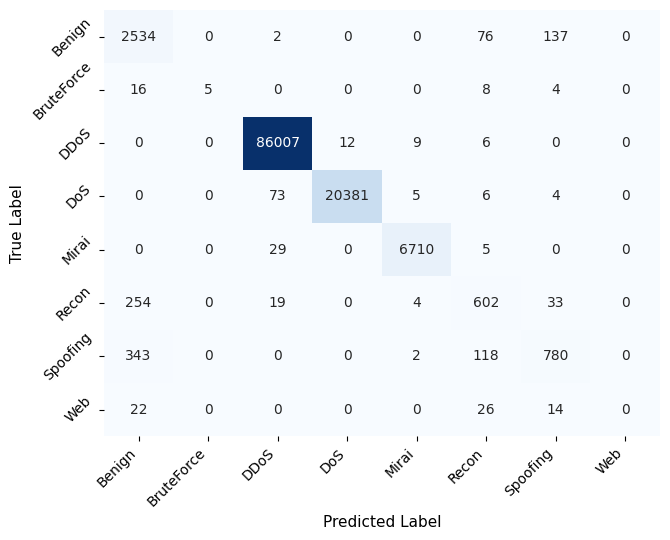

,Model,Representative_Run,Representative_Seed,Representative_F1_macro,Five_Run_Mean_F1_macro
0,DNN,2,43,0.687621,0.687557


All five-run DNN outputs were saved to:


In [27]:
representative_run_records = []


for model_name in [
    "DNN"
]:

    candidates = (
        representative_candidates_by_model[
            model_name
        ]
    )

    model_mean_f1 = float(
        all_run_results.loc[
            all_run_results[
                "Model"
            ] == model_name,
            "F1_macro",
        ].mean()
    )

    representative = min(
        candidates,
        key=lambda item: abs(
            item[
                "F1_macro"
            ]
            - model_mean_f1
        ),
    )

    representative_run_records.append(
        {
            "Model":
                model_name,

            "Representative_Run":
                representative[
                    "Run"
                ],

            "Representative_Seed":
                representative[
                    "Seed"
                ],

            "Representative_F1_macro":
                representative[
                    "F1_macro"
                ],

            "Five_Run_Mean_F1_macro":
                model_mean_f1,
        }
    )

    output_stem = (
        REPORT_OUTPUT_DIRECTORY
        / (
            "dnn_representative_"
            "confusion_matrix"
        )
    )

    plot_publication_confusion_matrix(
        y_test,
        representative[
            "Predictions"
        ],
        output_stem,
    )

    representative_report = (
        classification_report(
            y_test,
            representative[
                "Predictions"
            ],
            labels=np.arange(
                number_of_classes
            ),
            target_names=(
                label_encoder.classes_
            ),
            output_dict=True,
            zero_division=0,
        )
    )

    pd.DataFrame(
        representative_report
    ).transpose().to_csv(
        REPORT_OUTPUT_DIRECTORY
        / (
            "dnn_representative_"
            "classification_report.csv"
        )
    )


# Retain the original result-variable name.
representative_runs = (
    pd.DataFrame(
        representative_run_records
    )
)

representative_runs.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "representative_runs.csv",
    index=False,
)


display(
    representative_runs
)

print(
    "All five-run DNN outputs were saved to:"
)


In [28]:
import shutil

# Compress the entire Kaggle working/output directory
shutil.make_archive(
    "/kaggle/working/CICIoT2023Feature-AugmentedDNN_5_Seed_V3",
    "zip",
    "/kaggle/working"
)

print("Created: /kaggle/working/CICIoT2023Feature-AugmentedDNN_5_Seed_V3.zip")


Created: /kaggle/working/CICIoT2023Feature-AugmentedDNN_5_Seed_V3.zip


### Offline measure inference time 

In [ ]:
# ============================================================
# Classifier inference-time measurement using pretrained models
# ============================================================

import time
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path


# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
RESULT_DIRECTORY = Path(
    "CICIoT2023_DNN_5_seed_V3"
)

X_TEST_PATH = (
    RESULT_DIRECTORY
    / "X_test_scaled.npy"
)

TIMING_OUTPUT_PATH = (
    RESULT_DIRECTORY
    / "pretrained_model_inference_timing.csv"
)


# ------------------------------------------------------------
# Load exact test input used during evaluation
# ------------------------------------------------------------
X_test_scaled = np.load(
    X_TEST_PATH
)

N_TEST_SAMPLES = len(
    X_test_scaled
)


# ------------------------------------------------------------
# Timing protocol
# ------------------------------------------------------------
N_WARMUP_RUNS = 3
N_TIMING_RUNS = 5

RUN_SEEDS = [
    42,
    43,
    44,
    45,
    46,
]


# ------------------------------------------------------------
# Measure inference time for each pretrained model
# ------------------------------------------------------------
timing_records = []

for run_index, seed in enumerate(
    RUN_SEEDS,
    start=1,
):

    model_path = (
        RESULT_DIRECTORY
        / f"DNN_Seed_{run_index}"
        / f"dnn_seed_{seed}.keras"
    )

    print(
        f"\nLoading model: {model_path}"
    )

    model = tf.keras.models.load_model(
        model_path
    )


    # --------------------------------------------------------
    # Warm-up predictions
    # --------------------------------------------------------
    for _ in range(
        N_WARMUP_RUNS
    ):
        _ = model.predict(
            X_test_scaled,
            verbose=0,
        )


    # --------------------------------------------------------
    # Timed repetitions
    # --------------------------------------------------------
    repetition_times = []

    for repetition in range(
        1,
        N_TIMING_RUNS + 1,
    ):

        start_time = time.perf_counter()

        _ = model.predict(
            X_test_scaled,
            verbose=0,
        )

        inference_time_s = (
            time.perf_counter()
            - start_time
        )

        repetition_times.append(
            inference_time_s
        )

        timing_records.append(
            {
                "Seed":
                    seed,

                "Run":
                    run_index,

                "Repetition":
                    repetition,

                "Inference_Time_s":
                    inference_time_s,

                "Latency_ms_per_sample":
                    (
                        inference_time_s
                        / N_TEST_SAMPLES
                        * 1000.0
                    ),
            }
        )


    print(
        f"Seed {seed}: "
        f"{np.mean(repetition_times):.6f} s "
        f"± "
        f"{np.std(repetition_times, ddof=1):.6f} s"
    )


    del model

    tf.keras.backend.clear_session()


# ============================================================
# Save repetition-level results
# ============================================================
timing_df = pd.DataFrame(
    timing_records
)

timing_df.to_csv(
    TIMING_OUTPUT_PATH,
    index=False,
)


# ============================================================
# Calculate one timing estimate per independently trained model
# ============================================================
seed_summary_df = (
    timing_df
    .groupby(
        "Seed",
        as_index=False,
    )
    .agg(
        Mean_Inference_Time_s=(
            "Inference_Time_s",
            "mean",
        ),

        SD_Inference_Time_s=(
            "Inference_Time_s",
            "std",
        ),

        Mean_Latency_ms_per_sample=(
            "Latency_ms_per_sample",
            "mean",
        ),

        SD_Latency_ms_per_sample=(
            "Latency_ms_per_sample",
            "std",
        ),
    )
)


# ============================================================
# Five-seed final summary
# ============================================================
final_summary = {
    "Inference_Time_Mean_s":
        seed_summary_df[
            "Mean_Inference_Time_s"
        ].mean(),

    "Inference_Time_SD_s":
        seed_summary_df[
            "Mean_Inference_Time_s"
        ].std(
            ddof=1
        ),

    "Latency_Mean_ms_per_sample":
        seed_summary_df[
            "Mean_Latency_ms_per_sample"
        ].mean(),

    "Latency_SD_ms_per_sample":
        seed_summary_df[
            "Mean_Latency_ms_per_sample"
        ].std(
            ddof=1
        ),
}


print(
    "\nPer-seed timing summary:"
)

display(
    seed_summary_df
)

print(
    "\nFive-seed classifier inference summary:"
)

for key, value in final_summary.items():
    print(
        f"{key}: {value:.6f}"
    )

print(
    "\nSaved to:",
    TIMING_OUTPUT_PATH
)